In [1]:
# Purpose: Load the prepared Sahiwal soil dataset for feature engineering.

import pandas as pd
import numpy as np

data_path = "../data/processed/sahiwal_soil_dataset_scaled.csv"

soil_data = pd.read_csv(data_path)

print("Dataset shape:", soil_data.shape)
print("Columns:", soil_data.columns.tolist())

display(soil_data.head())

Dataset shape: (48807, 9)
Columns: ['longitude', 'latitude', 'ph', 'soc_g_kg', 'nitrogen_g_kg', 'clay_pct', 'sand_pct', 'silt_pct', 'cec_cmol_kg']


,longitude,latitude,ph,soc_g_kg,nitrogen_g_kg,clay_pct,sand_pct,silt_pct,cec_cmol_kg
0,73.166888,30.8821,7.9,7.9,0.92,25.2,43.9,30.9,15.6
1,73.169507,30.8821,7.8,8.0,0.92,24.4,43.2,32.4,15.3
2,73.172127,30.8821,7.8,8.4,1.02,23.8,43.3,32.9,15.3
3,73.174746,30.8821,7.9,9.5,1.11,24.2,41.2,34.6,15.4
4,73.177366,30.8821,7.9,9.4,1.10,24.2,40.9,34.9,14.8


In [2]:
# Purpose: Separate geographical features from soil properties.

location_features = ['longitude', 'latitude']

soil_features = [
    'ph',
    'soc_g_kg',
    'nitrogen_g_kg',
    'clay_pct',
    'sand_pct',
    'silt_pct',
    'cec_cmol_kg'
]

print("Geographical features:", location_features)
print("Soil properties:", soil_features)

print("\nNumber of geographical features:", len(location_features))
print("Number of soil properties:", len(soil_features))

Geographical features: ['longitude', 'latitude']
Soil properties: ['ph', 'soc_g_kg', 'nitrogen_g_kg', 'clay_pct', 'sand_pct', 'silt_pct', 'cec_cmol_kg']

Number of geographical features: 2
Number of soil properties: 7


In [3]:
# Purpose: Define input features and target variables for all three AI modules.

# Module 1: Predict all soil properties from geographical coordinates
X_geo = soil_data[location_features]
y_geo = soil_data[soil_features]

# Module 2: Predict CEC using selected soil properties
module2_features = [
    'ph', 'soc_g_kg', 'nitrogen_g_kg',
    'clay_pct', 'sand_pct', 'silt_pct'
]

X_property = soil_data[module2_features]
y_property = soil_data['cec_cmol_kg']

# Module 3: Classify soil texture using sand, silt, and clay
X_texture = soil_data[['sand_pct', 'silt_pct', 'clay_pct']]

print("Module 1:", X_geo.shape, "->", y_geo.shape)
print("Module 2:", X_property.shape, "->", y_property.shape)
print("Module 3:", X_texture.shape)

Module 1: (48807, 2) -> (48807, 7)
Module 2: (48807, 6) -> (48807,)
Module 3: (48807, 3)


In [4]:
%pip install soiltexture

Note: you may need to restart the kernel to use updated packages.


In [5]:
# Purpose: Import the USDA soil texture classification function.

from soiltexture import getTexture

print("Soil texture classification library imported successfully.")

Soil texture classification library imported successfully.


In [7]:
# Purpose: Inspect the arguments accepted by the soil texture classification function.

import inspect
from soiltexture import getTexture

print(inspect.signature(getTexture))
print(inspect.getdoc(getTexture))

(sand, clay, classification='USDA')
Provide soil texture given percentage of sand and clay.

Parameters
----------
sand : float
    Percentage of sand.
clay : float
    Percentage of clay.
classification : str, optional
    Classification scheme to use. Choices between 'USDA' (default), 
    'FAO', 'ISSS' or 'INTERNATIONAL'.

Return
------
texture : str
    Texture as a string.


In [8]:
# Purpose: Classify each soil observation using the USDA soil texture system.

from soiltexture import getTexture

soil_data['soil_texture'] = soil_data.apply(
    lambda row: getTexture(
        sand=row['sand_pct'],
        clay=row['clay_pct'],
        classification='USDA'
    ),
    axis=1
)

print("Soil texture classification completed.")

display(
    soil_data[['sand_pct', 'silt_pct', 'clay_pct', 'soil_texture']].head(10)
)

Soil texture classification completed.


,sand_pct,silt_pct,clay_pct,soil_texture
0,43.9,30.9,25.2,loam
1,43.2,32.4,24.4,loam
2,43.3,32.9,23.8,loam
3,41.2,34.6,24.2,loam
4,40.9,34.9,24.2,loam
5,40.6,34.7,24.7,loam
6,39.4,36.7,23.9,loam
7,40.0,37.2,22.8,loam
8,42.2,34.5,23.2,loam
9,42.3,34.4,23.3,loam


,observations
soil_texture,
loam,48203
clay loam,345
sandy clay loam,259


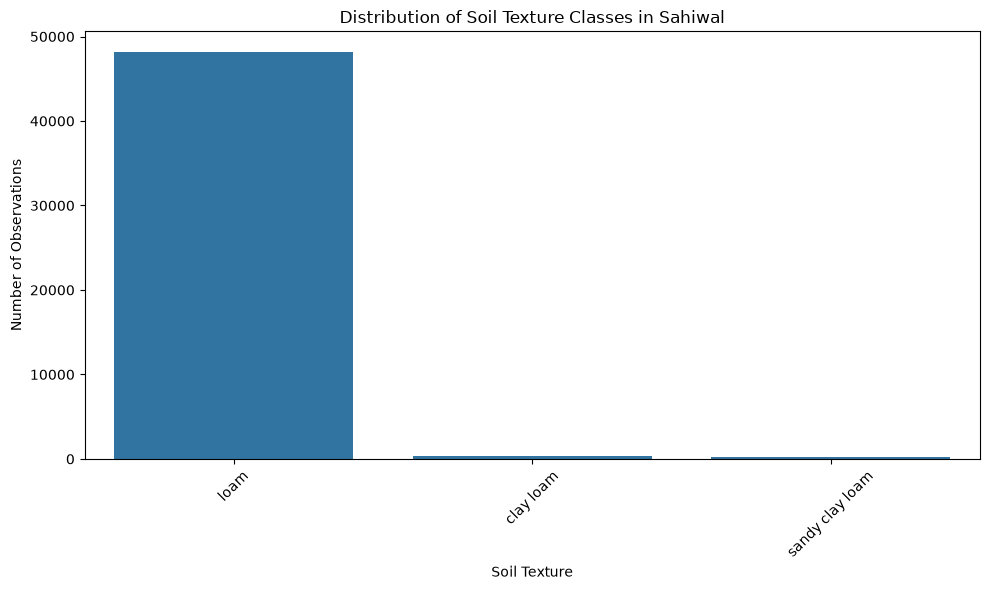

In [12]:
# Purpose: Count and visualize the distribution of USDA soil texture classes.

import matplotlib.pyplot as plt
import seaborn as sns

texture_counts = soil_data['soil_texture'].value_counts()

display(texture_counts.to_frame(name='observations'))

plt.figure(figsize=(10, 6))

sns.countplot(
    data=soil_data,
    x='soil_texture',
    order=texture_counts.index
)

plt.title('Distribution of Soil Texture Classes in Sahiwal')
plt.xlabel('Soil Texture')
plt.ylabel('Number of Observations')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# Purpose: Save the engineered dataset containing soil texture classifications.

output_path = "../data/processed/sahiwal_soil_dataset_engineered.csv"

soil_data.to_csv(output_path, index=False)

print("Engineered dataset saved successfully.")
print("Shape:", soil_data.shape)
print("Saved to:", output_path)

Engineered dataset saved successfully.
Shape: (48807, 10)
Saved to: ../data/processed/sahiwal_soil_dataset_engineered.csv


## Feature Engineering — Summary and Results

### 1. Dataset Preparation
Loaded the cleaned and scaled Sahiwal soil dataset containing **48,807 samples and 9 original features**.

### 2. Feature Sets for AI Modules

Prepared three feature sets for the planned AI capabilities:

- **Module 1 — Geographical Soil Prediction:** Uses longitude and latitude to predict seven soil properties.
- **Module 2 — Soil Property Prediction:** Uses pH, SOC, nitrogen, clay, sand, and silt to predict CEC.
- **Module 3 — Soil Texture Classification:** Uses soil properties to support soil texture classification.

### 3. Soil Texture Classification

Used the `soiltexture` Python library and its `getTexture()` function with the USDA classification system.

The classification was generated using sand and clay percentages, with silt implicitly calculated.

### 4. Soil Texture Distribution

| Soil Texture | Samples | Percentage |
|---|---:|---:|
| Loam | 48,203 | 98.76% |
| Clay Loam | 345 | 0.71% |
| Sandy Clay Loam | 259 | 0.53% |
| **Total** | **48,807** | **100%** |

**Observation:** The dataset is highly imbalanced because almost 99% of samples belong to the Loam class. Therefore, accuracy alone will not be a sufficient evaluation metric for the classification model. Macro F1-score and per-class performance will also be considered.

### 5. Important Modeling Consideration

Since soil texture labels are derived from sand and clay percentages, using those same percentages as model inputs would create target leakage. For the machine learning classification task, other soil properties will be considered as inputs.

### 6. Final Output

The engineered dataset was successfully saved:

`data/processed/sahiwal_soil_dataset_engineered.csv`

- Original features: 9
- Added feature: `soil_texture`
- Final dataset shape: **48,807 × 10**

### Conclusion

Feature engineering prepared the dataset and target variables required for the three planned AI modules. The next phase will focus on developing and evaluating machine learning models using appropriate validation strategies.